## Python Commands for Data Cleaning

#### 1. Import the standard libraries:
 - pandas
 - numpy
 - datetime

In [2]:
import pandas as pd
import numpy as np
import datetime as dt

#### 2. Bring in simulated annual financial statement data (similar to Compustat)
Use Pandas methods read_excel(), read_csv(), etc., to import data to Python.
 - Save the data file and code file under the same folder
 - First argument is the file name in quote, e.g., 'excel_file.xlsx'
 - Can add an argument, index_col=False, when a csv file is formatted poorly, and the read_csv method doesn't return meaningful results
 - Can add an argument, usecols=['col1','col2','col3'], if we only want a subset of columns

In [3]:
# slightly dif than in class bc i have in different folders - his was just the file name cause same location
comp1=pd.read_excel('C:\\Users\\fbw4vt\\OneDrive - University of Virginia\\COMM Semester 3\\1. Accounting Analytics\\Data_Files\\fina.xlsx',index_col=False)
comp1.head()

# side notes: 
# - gvkey created by compustat, vs cik created by sec (both unique identifiers)
# - oancf: operating cash flows; seq: stockholders equity

,gvkey,cik,datadate,tic,conm,ni,sale,cogs,oancf,at,lt,seq
0,1,66740,2012-12-31,MMM,3M Company,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0
1,1,66740,2014-12-31,MMM,3M Company,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0
2,1,66740,2013-12-31,MMM,3M Company,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0
3,1,66740,2013-12-31,MMM,3M Company,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0
4,1,66740,2016-12-31,MMM,3M Company,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0


**Inspect the data**
 - Use the info() method to generate a summary
 - Are variable types appropriate? If not, use the astype() method, e.g., df['column_name'] = df['column_name'].astype(float)
 - Which variables have missing values?
 - Do variables look right?

In [4]:
comp1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3502 entries, 0 to 3501
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   gvkey     3502 non-null   int64         
 1   cik       3502 non-null   int64         
 2   datadate  3502 non-null   datetime64[ns]
 3   tic       3502 non-null   object        
 4   conm      3502 non-null   object        
 5   ni        3502 non-null   float64       
 6   sale      3502 non-null   float64       
 7   cogs      2322 non-null   float64       
 8   oancf     3121 non-null   float64       
 9   at        3475 non-null   float64       
 10  lt        3473 non-null   float64       
 11  seq       3498 non-null   float64       
dtypes: datetime64[ns](1), float64(7), int64(2), object(2)
memory usage: 328.4+ KB


In [5]:
comp1['cik'] = comp1['cik'].astype(float) # doesn't rly matter but here's an example
comp1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3502 entries, 0 to 3501
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   gvkey     3502 non-null   int64         
 1   cik       3502 non-null   float64       
 2   datadate  3502 non-null   datetime64[ns]
 3   tic       3502 non-null   object        
 4   conm      3502 non-null   object        
 5   ni        3502 non-null   float64       
 6   sale      3502 non-null   float64       
 7   cogs      2322 non-null   float64       
 8   oancf     3121 non-null   float64       
 9   at        3475 non-null   float64       
 10  lt        3473 non-null   float64       
 11  seq       3498 non-null   float64       
dtypes: datetime64[ns](1), float64(8), int64(1), object(2)
memory usage: 328.4+ KB


#### 3. Remove unneeded variables
Use the drop() method, which has three arguments:
 - A list of columns to be removed, ['col1','col2']
 - axis=1, which indicates that we want to modify columns (axis=1) instead of rows (axis=0)
 - inplace=True, which indicates that we want to modify the original data instead of creating new data (note: the "T" is case-sensitive)

For this exercise, we won't need company name (`conm`) and ticker (`tic`).

In [6]:
comp1.drop(['conm','tic'], axis=1, inplace=True) 
comp1.head()

# way to do it without inplace, you reassign the df:
# comp1 = comp1.drop(['conm','tic'], axis=1)


,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0
3,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0


#### 4. Remove duplicates
Use drop_duplicates() method. 
 - Doesn't require arguments
 - But can add the following argument to drop duplicates based on specific columns: subset=['id', 'year'], keep='last'
 - Use keep='first' or keep='last' to keep the first or last record; this can follow a sort such as df.sort_values(by='at')

 [last is good for compustat bc often restated variables are the later one]

In [7]:
comp1 = comp1.drop_duplicates()
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0


#### 5. Create variables
We will discuss four types of variables:
 - Basic continuous variables (e.g., debt-to-assets ratio
 = lt/at)
 - Indicators/dummies (i.e., binary variables)
 - Date/year variables
 - Lagged variables (disucssed in detail later)

In [11]:
# basic continuous
comp1['dta'] = comp1['lt'] / comp1['at']
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,False
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,False
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,False
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,False
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,False


In [14]:
# dummy/indicator/binary
comp1['loss'] = (comp1['ni'] < 0).astype(int) # if didnt do parenthesis and astype it would store as True/False (a boolean)
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0


In [17]:
# complex new variables
comp1['loss2'] = ((comp1['ni'] < 0) & (comp1['at'] > 1000)).astype(int) # ampersand is AND in pandas, | is OR
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0,0
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0,0
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0


In [20]:
# example year variable
comp1['year'] = comp1['datadate'].dt.year # if we wanted to the month, add .month instead of year (and name the column smt like month) 
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0,0,2012
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0,0,2016
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017


**Important notes for lagged variables**
1. Use shift() method to create lagged variables
2. The shift() method generates the variables based on the index/row number, so it could generate meaningless results if the data is unsorted
3. Use groupby() method to generate lagged variables within groups (e.g., firms)
4. If there are missing years, need to ensure the previous row is exactly one year prior to the focal row

In [27]:
comp1['lag_at'] = comp1['at'].shift(1) # -1 would be the next row, e.g. t_+1, vs 1 as a positive is t_-1
comp1.head(10)

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0,0,2012,NaN
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014,33876.0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013,31269.0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0,0,2016,33550.0
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017,32906.0
6,1,66740.0,2018-12-31,5349.0,32765.0,16682.0,6439.0,36500.0,26652.0,9796.0,0.730192,0,0,2018,37987.0
7,1,66740.0,2019-12-31,4570.0,32136.0,17136.0,7070.0,44659.0,34533.0,10063.0,0.773260,0,0,2019,36500.0
8,281586,91142.0,2016-12-31,326.5,2685.9,1566.6,446.6,2891.0,1375.7,1515.3,0.475856,0,0,2016,44659.0
9,281586,91142.0,2017-12-31,296.5,2996.7,1758.0,326.4,3197.3,1548.5,1648.8,0.484315,0,0,2017,2891.0
10,281586,91142.0,2018-12-31,444.2,3187.9,1882.4,448.9,3071.5,1354.5,1717.0,0.440990,0,0,2018,3197.3


In [28]:
comp1['lag_at'] = comp1.groupby(['gvkey'])['at'].shift(1)
comp1.head(10)

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0,0,2012,NaN
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014,33876.0
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013,31269.0
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0,0,2016,33550.0
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017,32906.0
6,1,66740.0,2018-12-31,5349.0,32765.0,16682.0,6439.0,36500.0,26652.0,9796.0,0.730192,0,0,2018,37987.0
7,1,66740.0,2019-12-31,4570.0,32136.0,17136.0,7070.0,44659.0,34533.0,10063.0,0.773260,0,0,2019,36500.0
8,281586,91142.0,2016-12-31,326.5,2685.9,1566.6,446.6,2891.0,1375.7,1515.3,0.475856,0,0,2016,NaN
9,281586,91142.0,2017-12-31,296.5,2996.7,1758.0,326.4,3197.3,1548.5,1648.8,0.484315,0,0,2017,2891.0
10,281586,91142.0,2018-12-31,444.2,3187.9,1882.4,448.9,3071.5,1354.5,1717.0,0.440990,0,0,2018,3197.3


In [32]:
comp1 = comp1.sort_values(by=['gvkey', 'datadate']) # could have done by year as well (we've created that)
comp1['lag_at'] = comp1.groupby(['gvkey'])['at'].shift(1)
# the above code is fine except if you're missing a year the lag will be over two years.

# so you add a conditional, so basically its keep where it is the same, otherwise create missing variable
comp1['lag_at'] = comp1['lag_at'].where(comp1.groupby('gvkey').year.diff()==1, np.nan)  # also note that year here is not a method, but a variable (has to match what we set above)
comp1.head(10)

# don't have to memorize / write this longer one out on exam but understand what's going on here

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at
0,1,66740.0,2012-12-31,4444.000,29904.000,15685.000,NaN,33876.000,15836.000,17575.000,0.467470,0,0,2012,NaN
2,1,66740.0,2013-12-31,4659.000,30871.000,16106.000,NaN,33550.000,15602.000,17502.000,0.465037,0,0,2013,33876.000
1,1,66740.0,2014-12-31,4956.000,31821.000,16447.000,NaN,31269.000,18127.000,13109.000,0.579712,0,0,2014,33550.000
4,1,66740.0,2016-12-31,5050.000,30109.000,15040.000,6662.000,32906.000,22563.000,10298.000,0.685680,0,0,2016,NaN
5,1,66740.0,2017-12-31,4858.000,31657.000,16001.000,6240.000,37987.000,26365.000,11563.000,0.694053,0,0,2017,32906.000
6,1,66740.0,2018-12-31,5349.000,32765.000,16682.000,6439.000,36500.000,26652.000,9796.000,0.730192,0,0,2018,37987.000
7,1,66740.0,2019-12-31,4570.000,32136.000,17136.000,7070.000,44659.000,34533.000,10063.000,0.773260,0,0,2019,36500.000
2169,2575,1037646.0,2012-12-31,290.847,2341.528,811.204,327.704,2117.400,1290.181,827.219,0.609323,0,0,2012,NaN
2170,2575,1037646.0,2013-12-31,306.094,2378.972,794.915,345.928,2152.819,1217.767,935.052,0.565662,0,0,2013,2117.400
2171,2575,1037646.0,2014-12-31,338.241,2485.983,809.537,418.912,2009.110,1289.515,719.595,0.641834,0,0,2014,2152.819


Here is a ss of what happens if don't run that third line of code:

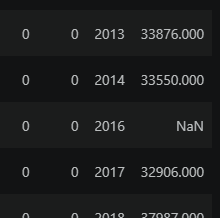

In [33]:
comp1['roa'] = comp1['ni'] / (comp1['at'] + comp1['lag_at']) * 2
comp1.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at,roa
0,1,66740.0,2012-12-31,4444.0,29904.0,15685.0,NaN,33876.0,15836.0,17575.0,0.467470,0,0,2012,NaN,NaN
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013,33876.0,0.138196
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014,33550.0,0.152918
4,1,66740.0,2016-12-31,5050.0,30109.0,15040.0,6662.0,32906.0,22563.0,10298.0,0.685680,0,0,2016,NaN,NaN
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017,32906.0,0.137052


#### 6. Filtering
To combine multiple conditions, list the conditions in `()`, and then use `&`, `|`, `~` as operators for `and`, `or`, and `not`, respectively. For example, comp1[(comp1['at']>100) & (comp1['roa'].notna())]

In [36]:
comp2 = comp1[(comp1['at'] > 100) & (comp1['roa'].notna())]
comp2.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at,roa
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013,33876.0,0.138196
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014,33550.0,0.152918
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017,32906.0,0.137052
6,1,66740.0,2018-12-31,5349.0,32765.0,16682.0,6439.0,36500.0,26652.0,9796.0,0.730192,0,0,2018,37987.0,0.143622
7,1,66740.0,2019-12-31,4570.0,32136.0,17136.0,7070.0,44659.0,34533.0,10063.0,0.773260,0,0,2019,36500.0,0.112618


In [38]:
comp3 = comp2.dropna(subset=['roa','lt','seq'])
comp3.head()

,gvkey,cik,datadate,ni,sale,cogs,oancf,at,lt,seq,dta,loss,loss2,year,lag_at,roa
2,1,66740.0,2013-12-31,4659.0,30871.0,16106.0,NaN,33550.0,15602.0,17502.0,0.465037,0,0,2013,33876.0,0.138196
1,1,66740.0,2014-12-31,4956.0,31821.0,16447.0,NaN,31269.0,18127.0,13109.0,0.579712,0,0,2014,33550.0,0.152918
5,1,66740.0,2017-12-31,4858.0,31657.0,16001.0,6240.0,37987.0,26365.0,11563.0,0.694053,0,0,2017,32906.0,0.137052
6,1,66740.0,2018-12-31,5349.0,32765.0,16682.0,6439.0,36500.0,26652.0,9796.0,0.730192,0,0,2018,37987.0,0.143622
7,1,66740.0,2019-12-31,4570.0,32136.0,17136.0,7070.0,44659.0,34533.0,10063.0,0.773260,0,0,2019,36500.0,0.112618


#### 7. Descriptive statistics
1. Use describe() method, which, by default, returns mean, std, min, max, and quartiles. Add arguments to obtain percentiles, e.g., [0.01]. returns the bottom percentile.
2. Use corr() method to obtain correlation.

#### 8. Outliers and winsorizastion
Outliers occur naturally or due to data entry errors. Outliers must be handled carefully to avoid biases and errors. We will focus on two ways to address the outlier problems: (1) truncation (i.e., deletion) and (2) winsorization (i.e., replacing outliers with "normal" value).

In [26]:
##truncation
varlist = ['at','roa']
high=.99
low=.01
for x in varlist:
    comp1.loc[(comp1[x]>comp1[x].quantile(high, interpolation='nearest'))
              |(comp1[x]<comp1[x].quantile(low, interpolation='nearest')),x]=np.nan

In [27]:
##winsorization
varlist = ['cogs','ni']
high=.99
low=.01
for x in varlist:
    comp1.loc[(comp1[x]>comp1[x].quantile(high, interpolation='nearest')),x]=comp1[x].quantile(high, interpolation='nearest')
for x in varlist:
    comp1.loc[(comp1[x]<comp1[x].quantile(low, interpolation='nearest')), x]=comp1[x].quantile(low, interpolation='nearest')

#### 9. Joins
Use merge() method. Specify four arguments: (1) the "left" DataFrame, (2) the "right" DataFrame, (3) the merge method, e.g., how='inner', and (4) on what variable(s), e.g., ['year'].
- 'inner' for inner join, 'left' for left outer join, 'right' for right outer join, and 'outer' for full outer join.
- if need to join on multiple variables (e.g., gvkey and year), then use on=['gvkey','year'].
- if the join on variables are of different names (e.g., cik and company_fkey), then use left_on='cik', right_on='company_fkey'.
- if need to join on multiple variables with different names, then use, e.g., left_on=['cik', 'year'], right_on=['company_fkey', 'fyear']. 